In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import sys
import matplotlib.pyplot as plt
import numpy as np
import os

sys.path.append('..')

from models.cifar10_autoencoder import CIFAR10Autoencoder
from trainers.autoencoder_trainer import AutoencoderTrainer
from models.cifar10_classifier import CIFAR10Classifier
from trainers.classifier_trainer import ClassifierTrainer

In [7]:
def show_ae_reconstructions(model, dataset, device='cuda', num_images=5):
    model.eval()  
    indices = np.random.choice(len(dataset), size=num_images, replace=False)

    fig, axes = plt.subplots(nrows=num_images, ncols=2, figsize=(4, 2*num_images))

    for i, idx in enumerate(indices):
        img, _ = dataset[idx]  
        img_tensor = img.unsqueeze(0).to(device)

        with torch.no_grad():
            reconstruction, _ = model(img_tensor) 

        original_np = img_tensor.cpu().squeeze().numpy()
        recon_np = reconstruction.cpu().squeeze().numpy()

        if len(original_np.shape) == 3:
            original_np = original_np[0] 
        if len(recon_np.shape) == 3:
            recon_np = recon_np[0]

        axes[i, 0].imshow(original_np)
        axes[i, 0].set_title("Original")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(recon_np)
        axes[i, 1].set_title("Reconstruction")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

In [3]:
data_path = os.path.join("..", "data")
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(0, translate=(0.1, 0.1)),
    transforms.ToTensor()
])
val_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
full_train_dataset = datasets.CIFAR10(root=data_path, train=True, download=True)
test_dataset   = datasets.CIFAR10(root=data_path, train=False, download=True)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset = TransformedSubset(val_subset, val_transform)
test_dataset = TransformedSubset(test_dataset, test_transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

Files already downloaded and verified
Files already downloaded and verified


Epoch [1] - Train Loss: 0.1042, Val Loss: 0.0777, Test Loss: 0.0778
              Train L1: 0.1042,  Val L1: 0.0777, Test L1: 0.0778
Epoch [2] - Train Loss: 0.0686, Val Loss: 0.0659, Test Loss: 0.0660
              Train L1: 0.0686,  Val L1: 0.0659, Test L1: 0.0660
Epoch [3] - Train Loss: 0.0613, Val Loss: 0.0611, Test Loss: 0.0612
              Train L1: 0.0613,  Val L1: 0.0611, Test L1: 0.0612
Epoch [4] - Train Loss: 0.0574, Val Loss: 0.0586, Test Loss: 0.0586
              Train L1: 0.0574,  Val L1: 0.0586, Test L1: 0.0586
Epoch [5] - Train Loss: 0.0548, Val Loss: 0.0583, Test Loss: 0.0584
              Train L1: 0.0548,  Val L1: 0.0583, Test L1: 0.0584
Epoch [6] - Train Loss: 0.0531, Val Loss: 0.0552, Test Loss: 0.0552
              Train L1: 0.0531,  Val L1: 0.0552, Test L1: 0.0552
Epoch [7] - Train Loss: 0.0523, Val Loss: 0.0535, Test Loss: 0.0534
              Train L1: 0.0523,  Val L1: 0.0535, Test L1: 0.0534
Epoch [8] - Train Loss: 0.0517, Val Loss: 0.0533, Test Loss: 0.0533
 

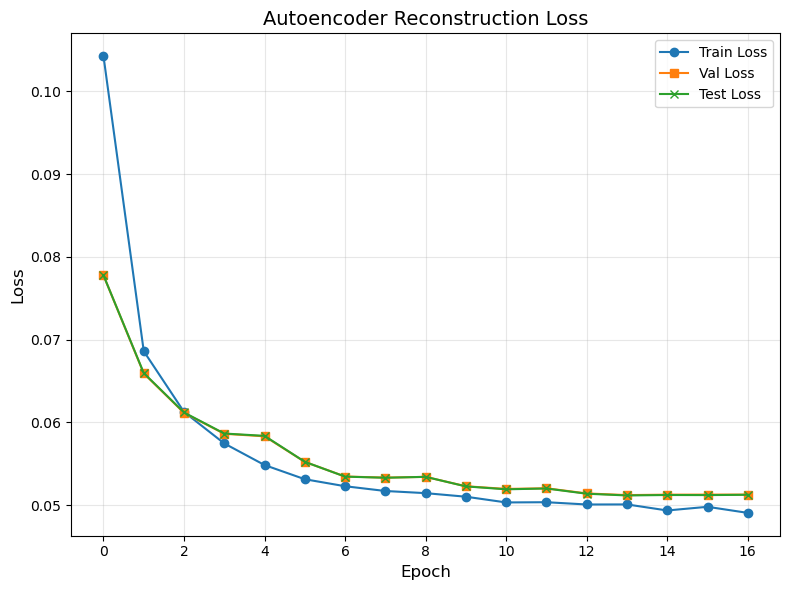

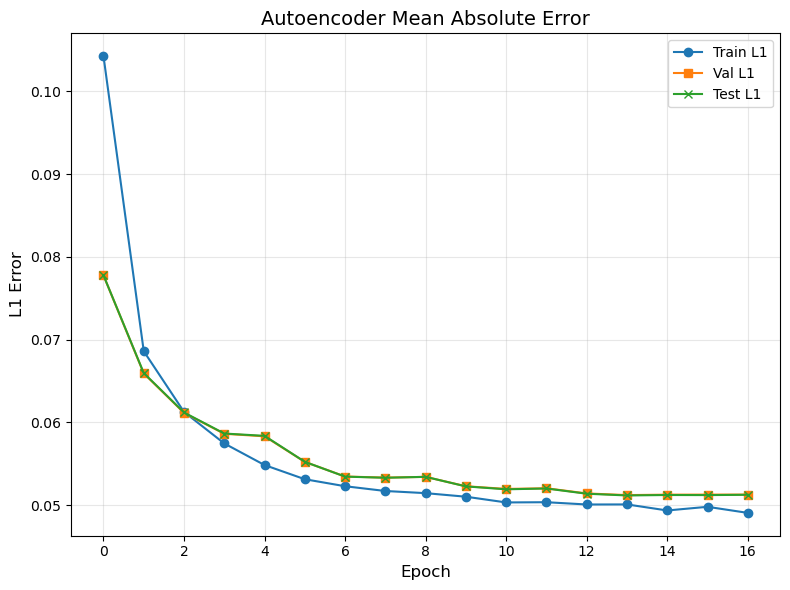

=== Final Autoencoder Metrics ===
Train ReconLoss: 0.0491
Val   ReconLoss: 0.0513
Test  ReconLoss: 0.0512
Train L1: 0.0491
Val   L1: 0.0513
Test  L1: 0.0512


In [5]:

autoencoder_l1_loss = CIFAR10Autoencoder(latent_dim=128)
autoencoder_trainer = AutoencoderTrainer(
model=autoencoder_l1_loss,
train_loader=train_loader,
val_loader=val_loader,
test_loader = test_loader,
criterion=torch.nn.L1Loss(),
device='cuda',
lr=5e-4,
num_epochs=100,
scheduler_type='plateau',
weight_decay=1e-5,
patience = 3
)
autoencoder_trainer.train()
autoencoder_trainer.plot_metrics()


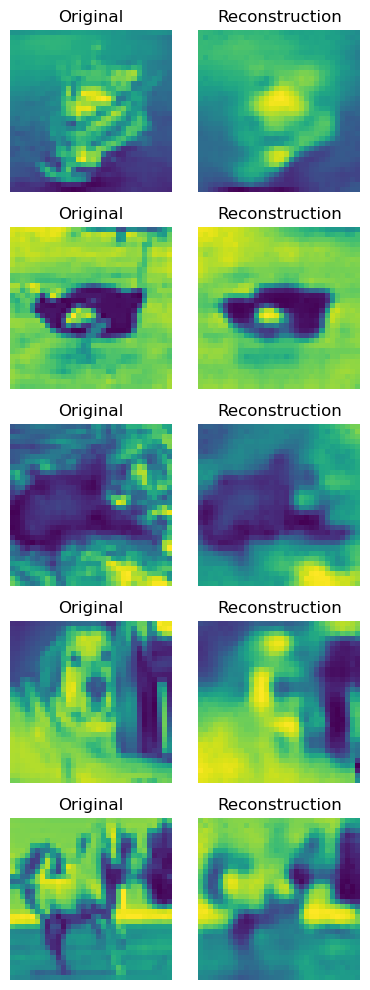

In [8]:
show_ae_reconstructions(autoencoder_l1_loss, test_dataset, device=device, num_images=5)

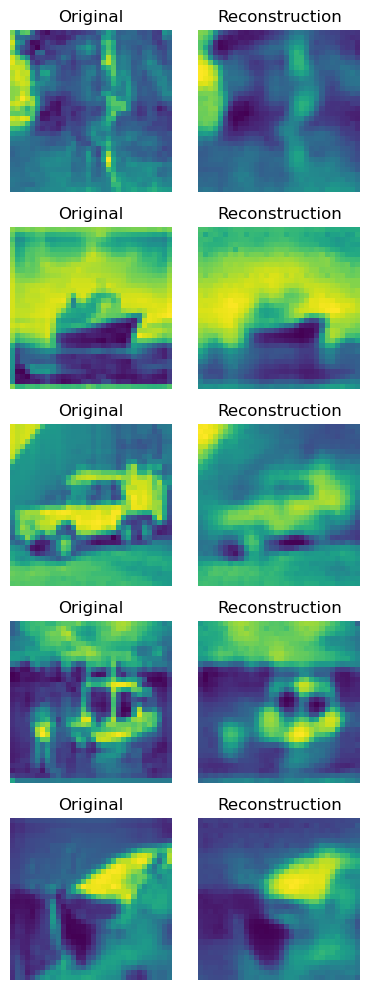

In [9]:
show_ae_reconstructions(autoencoder_l1_loss, test_dataset, device=device, num_images=5)

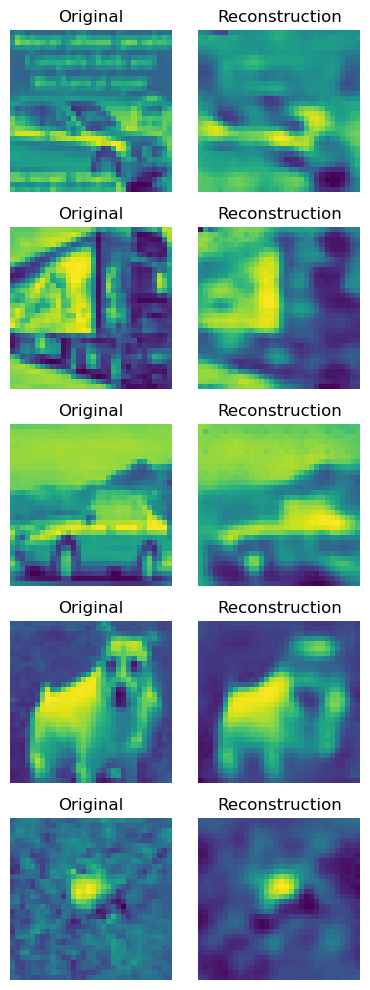

In [10]:
show_ae_reconstructions(autoencoder_l1_loss, test_dataset, device=device, num_images=5)